# Context relevance vs LLM judges

Cache-only comparison on the same traces and Qwen3.5 models as `context-relevance-plots.ipynb`. Context relevance uses **average log likelihood per context**. The three ablations favor the **lowest** step score; perplexity favors the **highest**. Ties select the earliest step. The LLM judge uses the full-run CSV; invalid responses count as wrong. Exclude the same invalid Dyck trace from both sources.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import make_scorer
from sklearn.model_selection import TunedThresholdClassifierCV

from experiment_setup import dc_pmi
from experiment_setup.benchmarks import load_examples
from experiment_setup.judge_metrics import score as judge_score

CACHE, RUNS = Path('cache'), Path('runs')
MODELS = {'4B': 'Qwen/Qwen3.5-4B', '9B': 'Qwen/Qwen3.5-9B', '27B': 'Qwen/Qwen3.5-27B'}
BENCHMARKS = ['MR-GSM8K', 'BIG-Bench-Mistake', 'ProcessBench']
KEYS = ['benchmark', 'task', 'uid']
METRIC_LABELS = {
    'perplexity': 'Perplexity',
    'dc_pmi_generic_domain': 'Fully ablated context relevance',
    'dc_pmi_question_ablation': 'Question ablated context relevance',
    'dc_pmi_history_ablation': 'History ablated context relevance',
}
examples = [e for task in load_examples().values() for e in task
            if not (e.benchmark == 'BIG-Bench-Mistake' and e.task == 'dyck_languages' and e.uid == '52')]
assert len(examples) == 8584
expected = pd.DataFrame([dict(benchmark=e.benchmark, task=e.task, uid=str(e.uid), label=e.label)
                         for e in examples])
assert not expected.duplicated(KEYS).any()

## Decision rule

For each trace, select the step with the highest **error-evidence** score (negative context relevance or positive perplexity). **Error-step detection accuracy** is the fraction of *erroneous* traces whose selected step is the annotated first error; it does not use the threshold. For **overall accuracy**, predict the selected step only when its evidence is at least the fitted threshold, otherwise predict NONE. This is exact first-error-or-NONE accuracy over *all* traces, not binary error-presence accuracy.

`TunedThresholdClassifierCV` is from **scikit-learn**, not SciPy. A custom scorer accounts for wrong locations (they are wrong regardless of the binary decision). Thresholds are tuned **separately for each benchmark, model and metric** over every distinct candidate evidence score plus all/none endpoints, giving the optimal in-sample threshold. Tuning and evaluation use the same traces (`cv='prefit'`): these are **optimistic in-sample comparisons**, not held-out estimates. The prefit estimator only passes the candidate score through; it does not learn from the labels.

In [2]:
def exact_location_accuracy(y_true, y_pred, *, candidate_correct):
    predicted_error = np.asarray(y_pred, dtype=bool)
    actual_error = np.asarray(y_true, dtype=bool)
    return np.mean((~predicted_error & ~actual_error) |
                   (predicted_error & candidate_correct))


def select_candidates(scores, metric):
    evidence = dc_pmi.error_evidence_score(scores, metric)
    candidates = scores.assign(evidence=evidence).loc[
        evidence.groupby([scores[k] for k in KEYS], sort=False).idxmax()
    ].copy()
    candidates['candidate_correct'] = candidates.step.eq(candidates.label)
    return candidates


def tune_accuracy(candidates):
    evidence = candidates.evidence.to_numpy()
    truth = candidates.label.notna().to_numpy()
    correct = candidates.candidate_correct.to_numpy(dtype=bool)
    X = evidence.reshape(-1, 1)
    thresholds = np.unique(np.r_[np.nextafter(evidence.min(), -np.inf),
                                 evidence,
                                 np.nextafter(evidence.max(), np.inf)])
    estimator = dc_pmi.RawScoreClassifier().fit(X, truth)
    tuned = TunedThresholdClassifierCV(
        estimator, cv='prefit', refit=False, response_method='decision_function',
        scoring=make_scorer(exact_location_accuracy, candidate_correct=correct),
        thresholds=thresholds,
    ).fit(X, truth)
    return tuned.best_score_, tuned.best_threshold_

In [3]:
rows = []
for model, model_id in MODELS.items():
    scores = dc_pmi.load_run(examples, model_id=model_id, average_ll=True,
                              cache_path=CACHE / f'dc_pmi_qwen35_{model.lower()}_arm.sqlite')
    scores['uid'] = scores.uid.astype(str)
    assert len(scores[KEYS].drop_duplicates()) == len(expected)
    assert scores[KEYS].drop_duplicates().merge(expected[KEYS], on=KEYS, validate='one_to_one').shape[0] == len(expected)
    judge = pd.read_csv(RUNS / f'llm_judge_qwen35_{model.lower()}_full_arm.csv',
                        dtype={'uid': str},
                        usecols=[*KEYS, 'label', 'prediction', 'parse_error'])
    judge = expected[KEYS].merge(judge, on=KEYS, how='left', validate='one_to_one', indicator=True)
    assert judge._merge.eq('both').all()
    judge = judge.drop(columns='_merge')
    assert judge.label.fillna(-1).eq(expected.label.fillna(-1)).all()
    for benchmark in BENCHMARKS:
        judge_group = judge.loc[judge.benchmark == benchmark]
        judge_result = judge_score(judge_group)
        rows.append(dict(benchmark=benchmark, model=model, method='LLM judge',
                         error_accuracy=judge_result['error_accuracy'],
                         overall_accuracy=judge_result['accuracy'], threshold=np.nan,
                         n=judge_result['n']))
        benchmark_scores = scores.loc[scores.benchmark == benchmark]
        for metric in dc_pmi.METRICS:
            candidates = select_candidates(benchmark_scores, metric)
            assert len(candidates) == len(judge_group)
            errors = candidates.label.notna()
            accuracy, threshold = tune_accuracy(candidates)
            rows.append(dict(benchmark=benchmark, model=model, method=METRIC_LABELS[metric],
                             error_accuracy=candidates.loc[errors, 'candidate_correct'].mean(),
                             overall_accuracy=accuracy, threshold=threshold, n=len(candidates)))
comparison = pd.DataFrame(rows)
display(comparison.round(3))


2026-11-07 08:51:49 INFO experiment_setup: Loading 8584 records from cache\dc_pmi_qwen35_4b_arm.sqlite
2026-11-07 08:51:54 INFO experiment_setup: Loaded records
2026-11-07 08:51:58 INFO experiment_setup: Loading 8584 records from cache\dc_pmi_qwen35_9b_arm.sqlite
2026-11-07 08:52:03 INFO experiment_setup: Loaded records
2026-11-07 08:52:06 INFO experiment_setup: Loading 8584 records from cache\dc_pmi_qwen35_27b_arm.sqlite
2026-11-07 08:52:12 INFO experiment_setup: Loaded records


,benchmark,model,method,error_accuracy,overall_accuracy,threshold,n
0,MR-GSM8K,4B,LLM judge,0.473,0.554,NaN,2999
1,MR-GSM8K,4B,Perplexity,0.025,0.476,180.411,2999
2,MR-GSM8K,4B,Fully ablated context relevance,0.225,0.476,0.320,2999
3,MR-GSM8K,4B,Question ablated context relevance,0.174,0.476,1.667,2999
4,MR-GSM8K,4B,History ablated context relevance,0.151,0.476,0.052,2999
5,BIG-Bench-Mistake,4B,LLM judge,0.254,0.246,NaN,2185
6,BIG-Bench-Mistake,4B,Perplexity,0.046,0.219,32.945,2185
7,BIG-Bench-Mistake,4B,Fully ablated context relevance,0.045,0.219,0.227,2185
8,BIG-Bench-Mistake,4B,Question ablated context relevance,0.280,0.254,0.319,2185
9,BIG-Bench-Mistake,4B,History ablated context relevance,0.000,0.219,0.029,2185


## Accuracy by benchmark and model

Each bar uses the same trace set for the corresponding model and benchmark. The threshold-free chart includes only erroneous traces; the thresholded chart includes all traces.

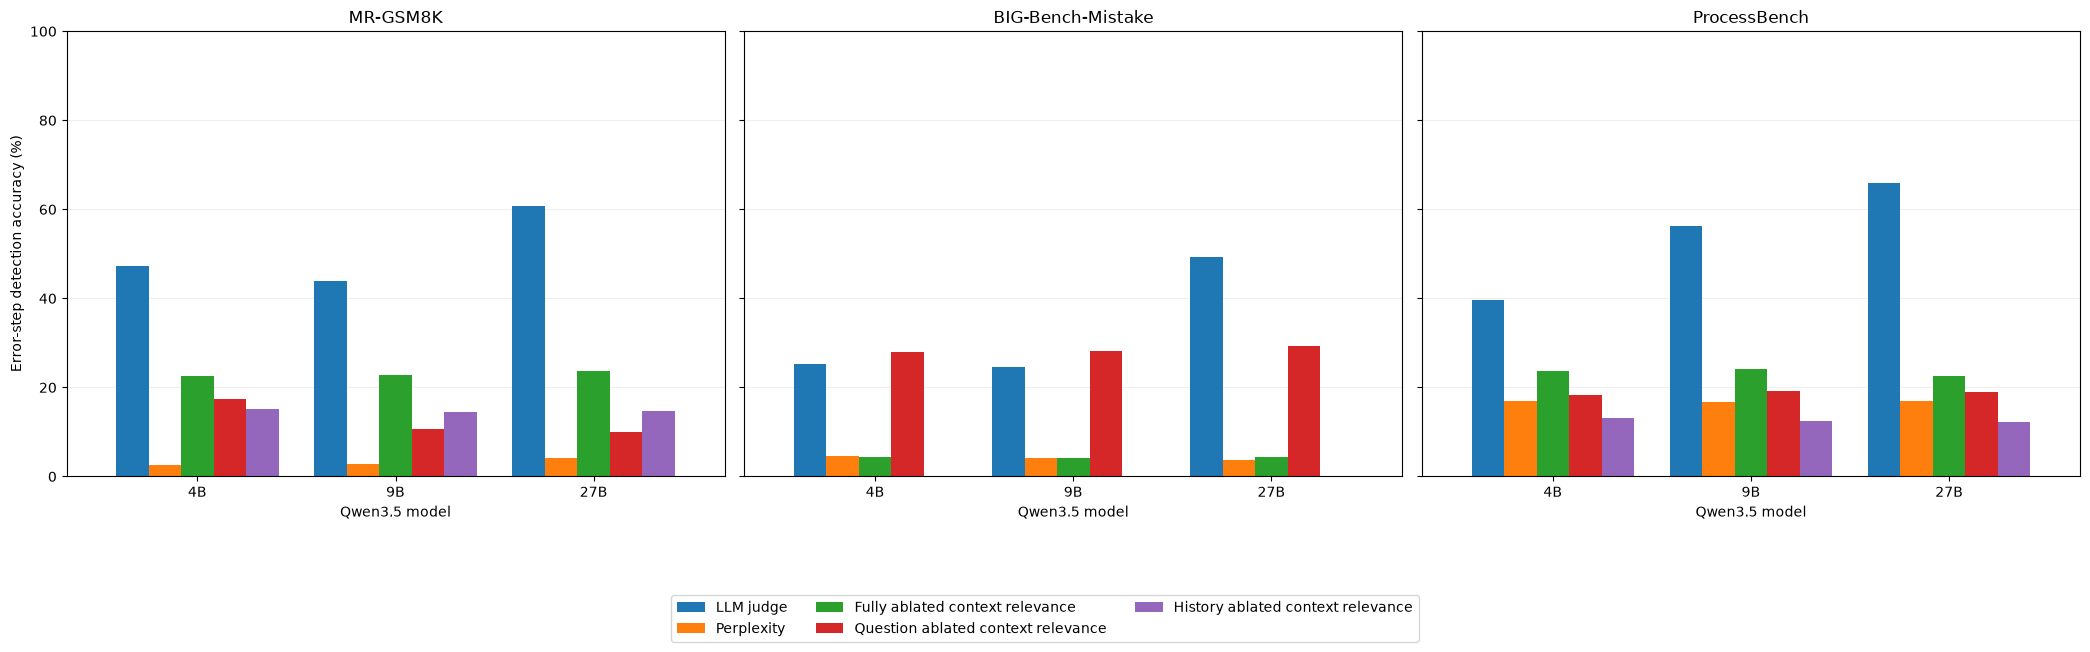

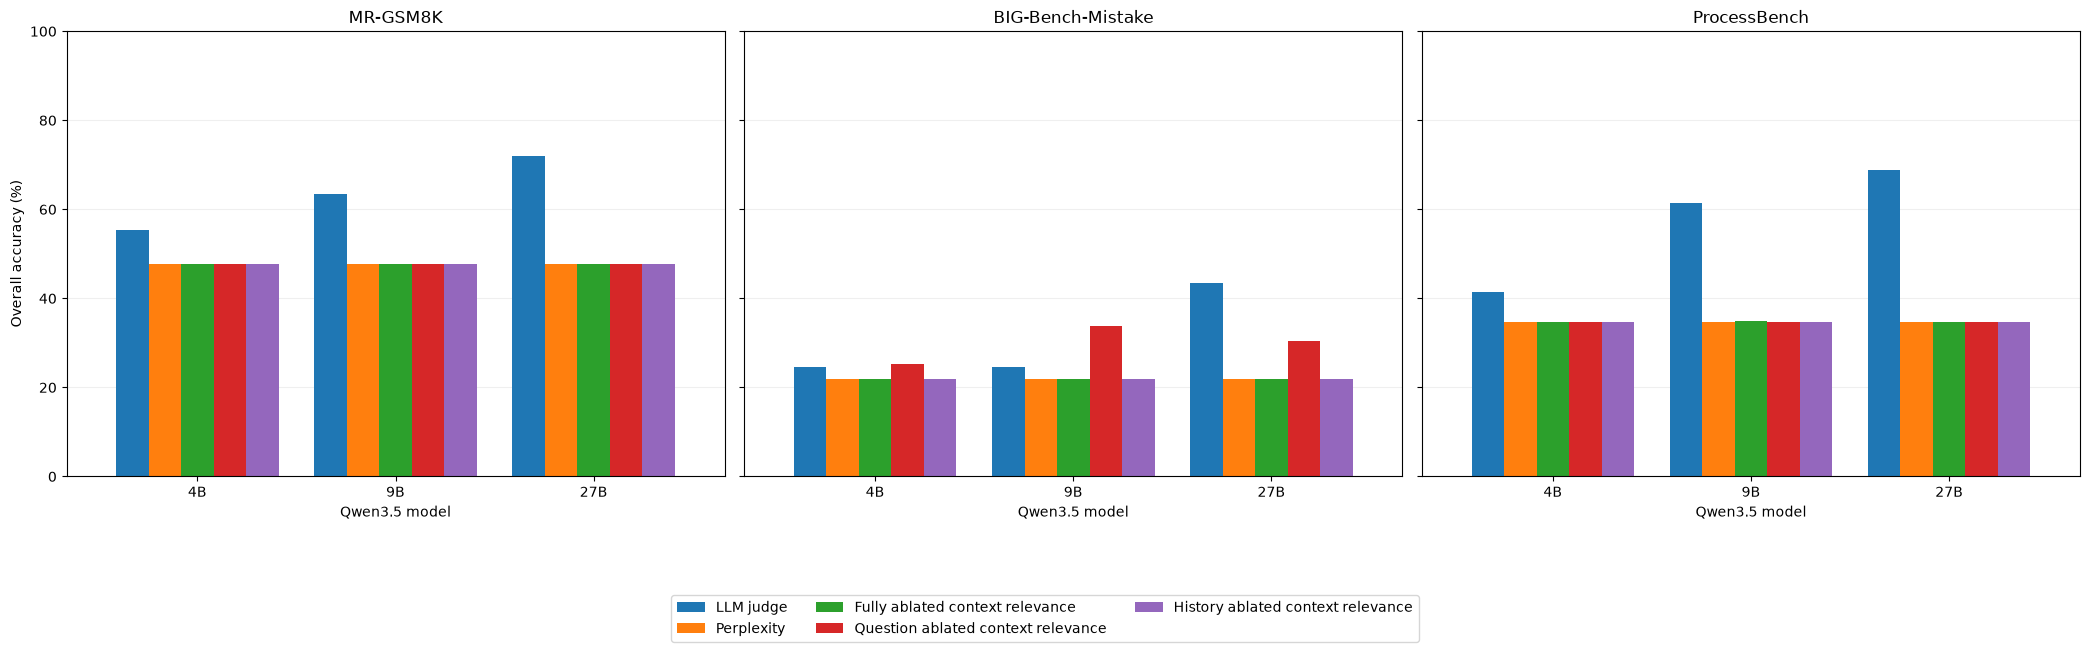

In [4]:
methods = ['LLM judge', *[METRIC_LABELS[m] for m in dc_pmi.METRICS]]
for column, ylabel in [
    ('error_accuracy', 'Error-step detection accuracy (%)'),
    ('overall_accuracy', 'Overall accuracy (%)'),
]:
    fig, axes = plt.subplots(1, len(BENCHMARKS), figsize=(21, 6), sharey=True)
    for ax, benchmark in zip(axes, BENCHMARKS):
        group = comparison.loc[comparison.benchmark == benchmark]
        values = group.pivot(index='model', columns='method', values=column)
        values.reindex(index=MODELS, columns=methods).mul(100).plot.bar(
            ax=ax, rot=0, legend=False, width=0.82)
        ax.set(title=benchmark, xlabel='Qwen3.5 model', ylabel=ylabel, ylim=(0, 100))
        ax.grid(axis='y', alpha=0.2)
        ax.set_axisbelow(True)
    fig.legend(axes[0].get_legend_handles_labels()[0], methods, loc='lower center',
               ncol=3, bbox_to_anchor=(0.5, -0.09))
    fig.tight_layout(rect=(0, 0.1, 1, 1))
    display(fig)
    plt.close(fig)


In [ ]:
# Thesis-ready comparisons. All bars use the same traces and exact-location denominator.
out = Path('../thesis/chapters/results')
selected = ['LLM judge', 'Fully ablated context relevance', 'Question ablated context relevance', 'Perplexity']
for column, filename in [
    ('error_accuracy', 'judge-vs-context-error.png'),
    ('overall_accuracy', 'judge-vs-context-overall.png'),
]:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True, constrained_layout=True)
    for ax, benchmark in zip(axes, BENCHMARKS):
        values = comparison[comparison.benchmark == benchmark].pivot(index='model', columns='method', values=column).reindex(index=MODELS, columns=selected)
        values.mul(100).plot.bar(ax=ax, rot=0, legend=False, width=.8)
        ax.set(title=benchmark, xlabel='', ylabel='Accuracy (%)', ylim=(0, 100))
        ax.grid(axis='y', alpha=.2)
    fig.legend(axes[0].get_legend_handles_labels()[0], selected, loc='lower center', ncol=2, bbox_to_anchor=(.5, -.16))
    fig.savefig(out / filename, dpi=220, bbox_inches='tight')
    plt.show()

# Full-run matched-task comparison (not the 100-example exploratory sample).
# Optimize exact accuracy by considering every threshold endpoint; this is the
# same decision rule/objective as tune_accuracy, without sklearn's constant-
# prediction guard (which fires for positive-only perplexity candidates).
def best_in_sample_accuracy(candidates):
    ordered = candidates.sort_values('evidence', ascending=False)
    truth = ordered.label.notna().to_numpy()
    correct = ordered.candidate_correct.to_numpy(dtype=bool)
    baseline = (~truth).sum()
    gains = np.where(correct, 1, -(~truth).astype(int))
    # Predictions above threshold: increase score only at complete tied-score groups.
    endpoints = ordered.evidence.ne(ordered.evidence.shift(-1)).to_numpy()
    return (baseline + max(0, *np.cumsum(gains)[endpoints])) / len(ordered)

shuffled_rows = []
for model, model_id in MODELS.items():
    task_examples = [e for e in examples if e.benchmark == 'BIG-Bench-Mistake' and e.task == 'tracking_shuffled_objects']
    task_scores = dc_pmi.load_run(task_examples, model_id=model_id, average_ll=True,
                                   cache_path=CACHE / f'dc_pmi_qwen35_{model.lower()}_arm.sqlite')
    task_scores['uid'] = task_scores.uid.astype(str)
    judge = pd.read_csv(RUNS / f'llm_judge_qwen35_{model.lower()}_full_arm.csv', dtype={'uid': str},
                        usecols=[*KEYS, 'label', 'prediction', 'parse_error'])
    judge = judge[(judge.benchmark == 'BIG-Bench-Mistake') & (judge.task == 'tracking_shuffled_objects')]
    assert len(judge) == len(task_examples) == 300
    j = judge_score(judge)
    shuffled_rows.append((model, 'LLM judge', j['error_accuracy'], j['accuracy']))
    for metric in dc_pmi.METRICS:
        candidate = select_candidates(task_scores, metric)
        error_accuracy = candidate.loc[candidate.label.notna(), 'candidate_correct'].mean()
        shuffled_rows.append((model, METRIC_LABELS[metric], error_accuracy, best_in_sample_accuracy(candidate)))
shuffled = pd.DataFrame(shuffled_rows, columns=['model', 'method', 'error_accuracy', 'overall_accuracy'])
print(shuffled.to_string(index=False, float_format=lambda v: f'{v:.3f}'))
for column, filename in [('error_accuracy', 'shuffled-error.png'), ('overall_accuracy', 'shuffled-overall.png')]:
    fig, ax = plt.subplots(figsize=(8, 4))
    shuffled.pivot(index='model', columns='method', values=column).reindex(index=MODELS, columns=selected).mul(100).plot.bar(ax=ax, rot=0, width=.8)
    ax.set(xlabel='Qwen3.5 model', ylabel='Accuracy (%)', ylim=(0, 100))
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    ax.grid(axis='y', alpha=.2)
    fig.tight_layout()
    fig.savefig(out / filename, dpi=220, bbox_inches='tight')
    plt.show()